In [16]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_pickle("dane.pkl")
df["Type_num"] = df["Type"].map({"A": 0, "B": 1, "C": 2})
df["Month"] = df["Date"].dt.month
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

print(df.shape)


(421570, 20)


In [ ]:
import joblib
from pathlib import Path

MODELE = Path(r"C:\Users\Alicja\Desktop\kurs-datascience\Data Science\Prognoza_sprzedazy\modele")

model_baz_final = joblib.load(MODELE / "model_bazowy.joblib")
model_cal_final = joblib.load(MODELE / "model_calkowity.joblib")
print("modele wczytane")

In [10]:
pary = df[["Store", "Dept", "Type_num", "Size"]].drop_duplicates(["Store", "Dept"])
tygodnie_2013 = pd.date_range("2013-01-04", "2013-12-27", freq="7D")

przyszlosc = pary.merge(pd.DataFrame({"Date": tygodnie_2013}), how="cross")
przyszlosc["Month"] = przyszlosc["Date"].dt.month
przyszlosc["WeekOfYear"] = przyszlosc["Date"].dt.isocalendar().week.astype(int)

print(przyszlosc.shape)
przyszlosc.head()

(173212, 7)


,Store,Dept,Type_num,Size,Date,Month,WeekOfYear
0,1,1,0,151315,2013-01-04,1,1
1,1,1,0,151315,2013-01-11,1,2
2,1,1,0,151315,2013-01-18,1,3
3,1,1,0,151315,2013-01-25,1,4
4,1,1,0,151315,2013-02-01,2,5


In [11]:
swieta_2013 = pd.to_datetime(["2013-02-08", "2013-09-06", "2013-11-29", "2013-12-27"])
przyszlosc["IsHoliday"] = przyszlosc["Date"].isin(swieta_2013).astype(float)

print(przyszlosc[przyszlosc["IsHoliday"] == 1]["Date"].unique())

<DatetimeArray>
['2013-02-08 00:00:00', '2013-09-06 00:00:00', '2013-11-29 00:00:00',
 '2013-12-27 00:00:00']
Length: 4, dtype: datetime64[ns]


In [12]:
markdown = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

cechy_zewn = ["Temperature", "Fuel_Price", "CPI", "Unemployment"] + markdown

typowe = df[df["Date"] > "2011-10-28"].groupby("Store")[cechy_zewn].mean().reset_index()
przyszlosc = przyszlosc.merge(typowe, on="Store", how="left")

print(przyszlosc.shape)
print("braki:", przyszlosc[cechy_zewn].isna().sum().sum())

(173212, 17)
braki: 0


In [14]:
markdown = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

bazowy = ["Store", "Dept", "Type_num", "Size", "Month", "WeekOfYear",
          "IsHoliday", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
calkowity = bazowy + markdown

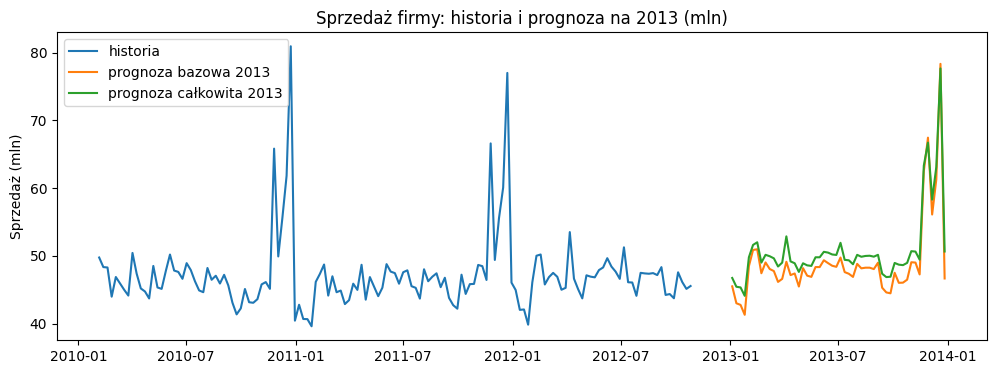

In [15]:
przyszlosc["prognoza_bazowa"] = model_baz_final.predict(przyszlosc[bazowy].astype(float)).clip(min=0)
przyszlosc["prognoza_calkowita"] = model_cal_final.predict(przyszlosc[calkowity].astype(float)).clip(min=0)

historia = df.groupby("Date")["Weekly_Sales"].sum() / 1_000_000
prognoza = przyszlosc.groupby("Date")[["prognoza_bazowa", "prognoza_calkowita"]].sum() / 1_000_000

plt.figure(figsize=(12, 4))
plt.plot(historia, label="historia")
plt.plot(prognoza["prognoza_bazowa"], label="prognoza bazowa 2013")
plt.plot(prognoza["prognoza_calkowita"], label="prognoza całkowita 2013")
plt.title("Sprzedaż firmy: historia i prognoza na 2013 (mln)")
plt.ylabel("Sprzedaż (mln)")
plt.legend()
plt.show()

In [17]:
wynik = przyszlosc[["Store", "Dept", "Date", "prognoza_bazowa", "prognoza_calkowita"]].copy()
wynik[["prognoza_bazowa", "prognoza_calkowita"]] = wynik[["prognoza_bazowa", "prognoza_calkowita"]].round(0)

print("Liczba wierszy:", len(wynik))
wynik[(wynik["Store"] == 1) & (wynik["Dept"] == 1)].head(10)

Liczba wierszy: 173212


,Store,Dept,Date,prognoza_bazowa,prognoza_calkowita
0,1,1,2013-01-04,16934.0,23187.0
1,1,1,2013-01-11,17221.0,23177.0
2,1,1,2013-01-18,17457.0,23497.0
3,1,1,2013-01-25,16501.0,23096.0
4,1,1,2013-02-01,24645.0,27459.0
5,1,1,2013-02-08,35790.0,35321.0
6,1,1,2013-02-15,44934.0,41988.0
7,1,1,2013-02-22,18794.0,24103.0
8,1,1,2013-03-01,18918.0,24825.0
9,1,1,2013-03-08,19828.0,25892.0


In [18]:
kolumny = ["Date"] + calkowity
wszystko = pd.concat([df[kolumny], przyszlosc[kolumny]], ignore_index=True)

def predict(store, dept, week):
    data = pd.to_datetime(week, dayfirst=True)
    tydzien = pd.offsets.Week(weekday=4).rollforward(data)
    wiersz = wszystko[(wszystko["Store"] == store) & (wszystko["Dept"] == dept) & (wszystko["Date"] == tydzien)]
    if wiersz.empty:
        return "Brak danych dla tego sklepu, działu i tygodnia."
    baz = max(model_baz_final.predict(wiersz[bazowy].astype(float))[0], 0)
    cal = max(model_cal_final.predict(wiersz[calkowity].astype(float))[0], 0)
    return {"tydzień kończący się": str(tydzien.date()),
            "sprzedaż bazowa": round(float(baz)),
            "sprzedaż całkowita": round(float(cal))}

print(predict(1, 1, "9/4/2010"))
print(predict(1, 1, "20/12/2013"))

{'tydzień kończący się': '2010-04-09', 'sprzedaż bazowa': 38322, 'sprzedaż całkowita': 39223}
{'tydzień kończący się': '2013-12-20', 'sprzedaż bazowa': 60271, 'sprzedaż całkowita': 50258}
